# 캠퍼스 전력수요 기온·캘린더·복합재해 시나리오 분석

`reference/regression_table.docx` 표 8의 최종 온도반응모형을 그대로 재현한 뒤, 기온·공휴일
·방학·기타 기상특보 시나리오가 연간 전력사용량·비용·CO2 배출에 미치는 영향을 계산한다.
표·그림은 이 노트북 안에서만 보이며 별도 파일로 저장하지 않는다.

1. **최종 모델 확정** — 자연 3차 스플라인(df=7), 당일·전일·전전일 기온, 특보 더미 제외
2. **기온 시나리오** — 임의 +1~+4℃ 및 실제 SSP2-4.5/SSP5-8.5(2030·2050년대) → 연간 사용량·분포
3. **캘린더 시나리오** — 공휴일·방학 (유의성 검토로 선정)
4. **비용** — 전기요금(교육용을 고압A)·탄소배출권 가격 적용
5. **복합재해 유의성(레질리언스)** — 폭염 외 모든 특보·주의보 전수 검토

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import gaussian_kde

plt.rcParams["font.family"] = "Malgun Gothic"     # 한글 폰트 (없으면 축 제목이 네모로 깨짐)
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

d = pd.read_csv("data/data_long.csv", parse_dates=["date"]).sort_values("date").reset_index(drop=True)
d["lnusage"] = np.log(d["usage_kwh"])
d["temp_lag1"] = d["temp_c"].shift(1)
d["temp_lag2"] = d["temp_c"].shift(2)
d["year"] = d["date"].dt.year
d["month"] = d["date"].dt.month
d["humidity_bin"] = pd.qcut(d["humidity_pct"], 6, labels=False)
est = d.dropna(subset=["lnusage", "temp_c", "temp_lag1", "temp_lag2", "humidity_pct", "precip_mm"]).copy()

print(f"데이터: data/data_long.csv (일별 5년) | 기간 {est['date'].min().date()} ~ {est['date'].max().date()} "
      f"| N={len(est)}")

데이터: data/data_long.csv (일별 5년) | 기간 2021-09-05 ~ 2026-09-02 | N=1819


## 1. 최종 temperature-response 모델 확정

`reference/regression_table.docx` 표 8과 동일한 스펙:

```
ln(usage_kwh) ~ 자연3차스플라인(당일·전일·전전일 기온, 각 df=7) + 습도 bin(6분위) + 강수량
              + 공휴일 + 방학 + 시험기간 + 요일 FE + 월 FE + 연도 FE
```

특보 더미는 제외. 표준오차 Newey–West HAC(15일). 문서 기준 N=1,820, R²=0.9147.
습도 bin 경계는 문서에 明시되지 않아 분위수(6등분)로 재구성(시나리오에서는 실측값 유지라
결과에 영향 미미). 당일·전일·전전일 스플라인 3개가 서로 강하게 상관돼(1일 자기상관 큼)
`rank-deficient` 경고가 뜨지만, 개별 계수가 아니라 합친 예측값만 쓰므로 문제되지 않는다
— 바로 아래 검증에서 확인.

In [2]:
formula = ("lnusage ~ cr(temp_c, df=7) + cr(temp_lag1, df=7) + cr(temp_lag2, df=7) "
           "+ C(humidity_bin) + precip_mm + holiday + vacation + exam_period "
           "+ C(day_of_week) + C(month) + C(year)")
res = smf.ols(formula, data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
smear = np.exp(res.resid).mean()                       # Duan(1983) 재변환 편향 보정계수
n_years = (est["date"].max() - est["date"].min()).days / 365.25

print(f"N = {res.nobs:.0f}   (문서 N=1,820)")
print(f"R2 = {res.rsquared:.4f}   (문서 R2=0.9147)")
print(f"smearing factor = {smear:.5f}  (1에 가까울수록 재변환 편향 작음)")

ctrl = ["precip_mm", "holiday", "vacation", "exam_period"]
pd.DataFrame({
    "coef_ln": [res.params[c] for c in ctrl],
    "se": [res.bse[c] for c in ctrl],
    "pvalue": [res.pvalues[c] for c in ctrl],
    "pct_effect": [(np.exp(res.params[c]) - 1) * 100 if c != "precip_mm" else np.nan for c in ctrl],
}, index=ctrl)

N = 1819   (문서 N=1,820)
R2 = 0.9149   (문서 R2=0.9147)
smearing factor = 1.00108  (1에 가까울수록 재변환 편향 작음)


C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\253082602.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res = smf.ols(formula, data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


,coef_ln,se,pvalue,pct_effect
precip_mm,-0.000,0.000,0.140,NaN
holiday,-0.143,0.010,0.000,-13.289
vacation,-0.018,0.008,0.031,-1.796
exam_period,0.005,0.006,0.355,0.544


In [3]:
# 15C 대비 반응 재현: 표8의 정상상태(당일=전일=전전일=T) 시나리오와 대조
def representative_row():
    r = est.iloc[[0]].copy()
    r[["holiday", "vacation", "exam_period", "precip_mm"]] = 0
    r["humidity_bin"] = int(est["humidity_bin"].median())
    r["day_of_week"] = "Wednesday"
    r["month"] = 6
    r["year"] = int(est["year"].median())
    return r


def steady_state_pct(temps):
    base = representative_row()
    rows = pd.concat([base.assign(temp_c=T, temp_lag1=T, temp_lag2=T) for T in temps], ignore_index=True)
    pred = res.predict(rows)
    pred15 = res.predict(base.assign(temp_c=15, temp_lag1=15, temp_lag2=15)).iloc[0]
    return (np.exp(pred.values - pred15) - 1) * 100


check_temps = [-10, -5, 0, 5, 10, 15, 20, 25, 28, 30, 32, 34, 36]
doc_values = [47.2, 33.2, 20.5, 8.9, -0.0, 0.0, 13.6, 29.2, 40.1, 48.2, 56.8, 65.8, 75.4]
check = pd.DataFrame({"temp_c": check_temps, "재현값(%)": steady_state_pct(check_temps), "문서값(%,표8)": doc_values})
check["차이(%p)"] = check["재현값(%)"] - check["문서값(%,표8)"]
check

,temp_c,재현값(%),"문서값(%,표8)",차이(%p)
0,-10,46.948,47.200,-0.252
1,-5,33.206,33.200,0.006
2,0,20.473,20.500,-0.027
3,5,8.767,8.900,-0.133
4,10,-0.110,-0.000,-0.110
5,15,0.000,0.000,0.000
6,20,13.415,13.600,-0.185
7,25,28.877,29.200,-0.323
8,28,39.736,40.100,-0.364
9,30,47.951,48.200,-0.249


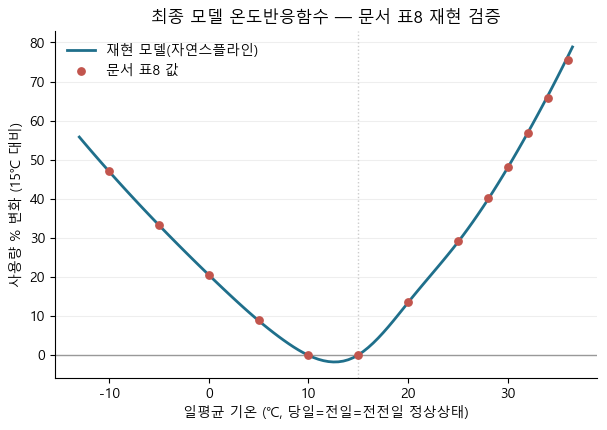

In [4]:
fine_t = np.arange(-13, 37, 0.5)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(0, color="#999999", lw=1)
ax.axvline(15, color="#cccccc", lw=1, ls=":")
ax.plot(fine_t, steady_state_pct(fine_t), color="#1f6f8b", lw=2, label="재현 모델(자연스플라인)")
ax.scatter(check_temps, doc_values, color="#c2554d", zorder=3, s=28, label="문서 표8 값")
ax.set_xlabel("일평균 기온 (℃, 당일=전일=전전일 정상상태)")
ax.set_ylabel("사용량 % 변화 (15℃ 대비)")
ax.set_title("최종 모델 온도반응함수 — 문서 표8 재현 검증")
ax.legend(frameon=False)
ax.grid(axis="y", color="#eeeeee", lw=0.8)
plt.show()

13개 대조점 모두 0.3%p 안팎으로 일치 (극단값 36℃에서 최대 0.86%p) — 이 모델로
이후 모든 시나리오를 계산한다.

## 2. 기온상승 시나리오 — 임의 +1~+4℃ & 실제 SSP2-4.5/SSP5-8.5

기존 5년 일별 기온(당일·전일·전전일 전부, 즉 시계열 전체)에 기온만 더하고 나머지
(습도·강수·공휴일/방학/시험기간·요일/월/연도)는 실측값 그대로 유지하는 delta-shift로
연간 사용량을 재예측한다 — PNAS(Auffhammer et al. 2017)와 같은 방법. 로그모형이라
`exp(예측값)`을 그대로 쓰면 재변환 편향이 생기므로 Duan smearing으로 보정.

**실제 SSP 시나리오 출처**: 국립기상과학원·기상청 SSP 기반 남한상세 기후변화 시나리오
(1km, 기준기간 2000–2019). 근미래(2021–2040, "2030년대")·중미래(2041–2060, "2050년대")
남한 평균 기온 상승폭:

| 시나리오 | 2030년대 | 2050년대 |
| --- | --- | --- |
| SSP2-4.5 | +1.2℃ | +2.2℃ |
| SSP5-8.5 | +1.4℃ | +2.8℃ |

주의: 수원 격자 특이값이 아니라 남한 평균(지역별 상세 시나리오는 climate.go.kr 지도에서
직접 골라야 해 자동 수집 불가) — 경기도 자체 추정치(2050년대 +2.5℃)와 비교해 큰 괴리는
없어 근사치로 사용.

In [5]:
def simulate_usage(delta_c):
    # 기온만 delta_c 만큼 이동한 5년 패널의 일별 예측 사용량(kWh) 배열
    sc = est.copy()
    sc["temp_c"] = est["temp_c"] + delta_c
    sc["temp_lag1"] = est["temp_lag1"] + delta_c
    sc["temp_lag2"] = est["temp_lag2"] + delta_c
    return np.exp(res.predict(sc)) * smear


SCENARIOS_TEMP = {"+0\u2103(기준)": 0, "+1\u2103": 1, "+2\u2103": 2, "+3\u2103": 3, "+4\u2103": 4,
                  "SSP2-4.5_2030s": 1.2, "SSP2-4.5_2050s": 2.2,
                  "SSP5-8.5_2030s": 1.4, "SSP5-8.5_2050s": 2.8}
usage_by_scn = {name: simulate_usage(dt) for name, dt in SCENARIOS_TEMP.items()}
CO2_FACTOR = 0.4541  # tCO2eq / MWh, 환경부 온실가스종합정보센터 '24

base_mwh = usage_by_scn["+0\u2103(기준)"].sum() / 1000 / n_years
temp_scen = pd.DataFrame([
    {"시나리오": name, "\u0394T(\u2103)": dt, "연평균 MWh": arr.sum() / 1000 / n_years}
    for (name, dt), arr in zip(SCENARIOS_TEMP.items(), usage_by_scn.values())
])
temp_scen["기준 대비 %"] = (temp_scen["연평균 MWh"] - base_mwh) / base_mwh * 100
temp_scen["추가 MWh"] = temp_scen["연평균 MWh"] - base_mwh
temp_scen["추가 tCO2eq"] = temp_scen["추가 MWh"] * CO2_FACTOR
temp_scen.style.format({"연평균 MWh": "{:,.0f}", "기준 대비 %": "{:+.2f}%",
                         "추가 MWh": "{:,.0f}", "추가 tCO2eq": "{:,.0f}"})

,시나리오,ΔT(℃),연평균 MWh,기준 대비 %,추가 MWh,추가 tCO2eq
0,+0℃(기준),0.000000,"87,536",+0.00%,0,0
1,+1℃,1.000000,"88,147",+0.70%,612,278
2,+2℃,2.000000,"88,904",+1.56%,"1,368",621
3,+3℃,3.000000,"89,808",+2.60%,"2,272","1,032"
4,+4℃,4.000000,"90,860",+3.80%,"3,324","1,510"
5,SSP2-4.5_2030s,1.200000,"88,287",+0.86%,751,341
6,SSP2-4.5_2050s,2.200000,"89,073",+1.76%,"1,537",698
7,SSP5-8.5_2030s,1.400000,"88,432",+1.02%,897,407
8,SSP5-8.5_2050s,2.800000,"89,615",+2.38%,"2,080",944


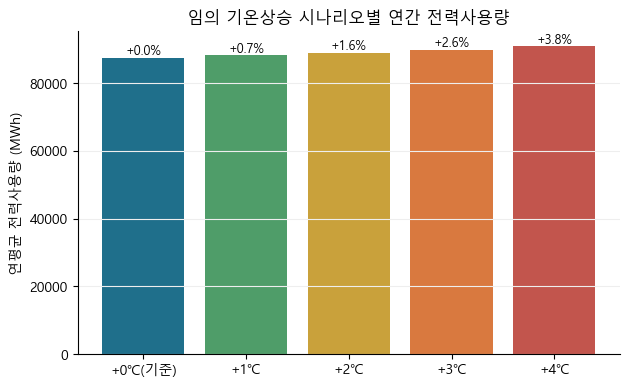

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.2))
arb = temp_scen[temp_scen["\u0394T(\u2103)"].isin([0, 1, 2, 3, 4])].sort_values("\u0394T(\u2103)")
colors = ["#1f6f8b", "#4f9d69", "#c9a13b", "#d9793f", "#c2554d"]
ax.bar(arb["시나리오"], arb["연평균 MWh"], color=colors)
for x, y, p in zip(arb["시나리오"], arb["연평균 MWh"], arb["기준 대비 %"]):
    ax.text(x, y, f"{p:+.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("연평균 전력사용량 (MWh)")
ax.set_title("임의 기온상승 시나리오별 연간 전력사용량")
ax.grid(axis="y", color="#eeeeee", lw=0.8)
plt.show()

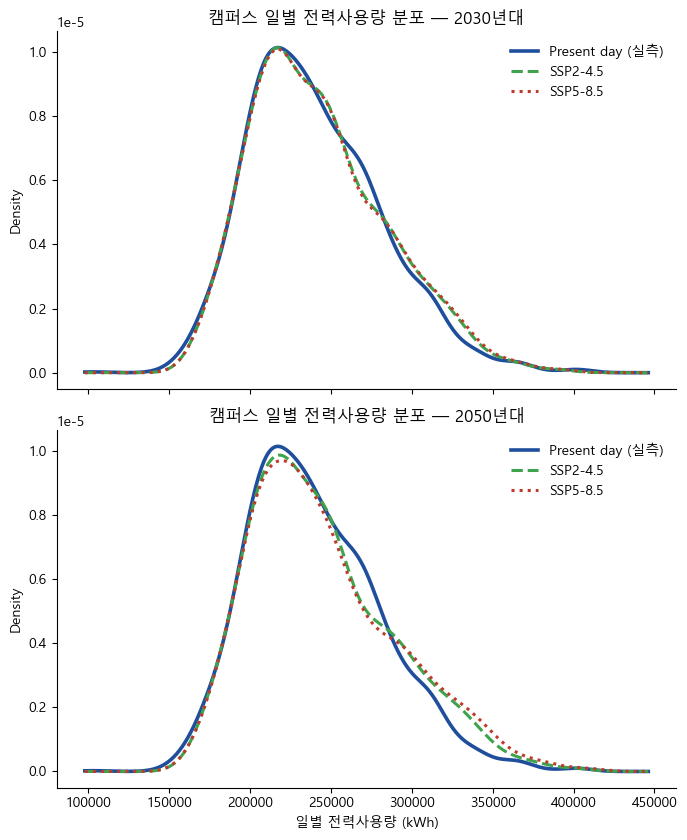

In [7]:
# Fig.2(PNAS) 스타일: present(실측) vs SSP 시나리오 KDE, 2030년대/2050년대 2패널
usage_present = est["usage_kwh"].to_numpy()
all_vals = np.concatenate([usage_present] + list(usage_by_scn.values()))
grid = np.linspace(all_vals.min() * 0.95, all_vals.max() * 1.05, 400)
kde = lambda x: gaussian_kde(x)(grid)

fig, axes = plt.subplots(2, 1, figsize=(7, 8.5), sharex=True)
panels = [("2030년대", "SSP2-4.5_2030s", "SSP5-8.5_2030s"), ("2050년대", "SSP2-4.5_2050s", "SSP5-8.5_2050s")]
for ax, (label, k245, k585) in zip(axes, panels):
    ax.plot(grid, kde(usage_present), color="#1f4e9c", lw=2.6, label="Present day (실측)")
    ax.plot(grid, kde(usage_by_scn[k245]), color="#3fa34d", lw=2.2, ls="--", label="SSP2-4.5")
    ax.plot(grid, kde(usage_by_scn[k585]), color="#c0392b", lw=2.2, ls=":", label="SSP5-8.5")
    ax.set_title(f"캠퍼스 일별 전력사용량 분포 — {label}", fontsize=12)
    ax.set_ylabel("Density")
    ax.legend(frameon=False, loc="upper right")
axes[-1].set_xlabel("일별 전력사용량 (kWh)")
plt.tight_layout()
plt.show()

기온이 오를수록 실측(파랑)과 같은 비대칭 분포가 그대로 오른쪽으로 밀린다. 2030년대는
두 SSP가 거의 안 갈라지고 2050년대에서 SSP5-8.5의 오른쪽 꼬리가 눈에 띄게 늘어남 — PNAS
Fig.2와 같은 패턴. (원래 Fig.2는 daily peak 기준인데, peak는 15분 자료가 1년뿐이라
bridge 모델을 더 거쳐야 해서 불확실성이 커진다 — 여기서는 5년 모델이 바로 설명하는
총사용량으로 재현했다.)

## 3. 캘린더 시나리오 — 공휴일·방학

기온 외에 문서에서 확인 가능한 캘린더 통제는 공휴일·방학·시험기간·강수량 네 가지.
**최종 모델 안에서의 유의성**으로 시나리오 대상을 정한다(1절 표 참고) —
`holiday`(-13.3%, p<0.001)·`vacation`(-1.8%, p=0.031)만 유의, `exam_period`·`precip_mm`은
비유의라 제외. 폭염특보 더미도 최종 모델에 다시 넣으면 우리 데이터로도 비유의(주의보
p=0.13, 경보 p=0.53) — 문서 표8 각주와 같은 결론이라 제외 근거가 하나 더 확보됨.

`holiday`는 이 프로젝트에서 **공식 공휴일 또는 일요일**(=저활동 비운영일)로 정의된
플래그다. "+N일/년" 시나리오는 "폭염 등으로 연간 N일만큼 추가 휴교·재택 전환이
일어난다"는 상황으로 이해하면 된다. 대상일은 평일·비공휴일·비방학·비시험기간 중
연대순으로 앞선 날을 (연평균 N일이 되도록) 골라 플래그만 바꾼다 — 요일·월·연도 FE가
따로 있어 어떤 날을 고르든 결과는 같다.

In [8]:
def flip_scenario(flag_col, n_total, other_flags=("holiday", "vacation", "exam_period")):
    elig = est.copy()
    mask = elig[flag_col] == 0
    for c in other_flags:
        if c != flag_col:
            mask &= elig[c] == 0
    mask &= ~elig["day_of_week"].isin(["Saturday", "Sunday"])
    idx = elig[mask].sort_values("date").index[: n_total]
    sc = est.copy()
    sc.loc[idx, flag_col] = 1
    return sc, len(idx)


def annual_mwh(df):
    return (np.exp(res.predict(df)) * smear).sum() / 1000 / n_years


CAL_SCENARIOS = [("공휴일", "holiday", [3, 6, 9], "일/년"), ("방학", "vacation", [1, 2, 3], "주/년")]
cal_rows = []
for label, col, steps, unit in CAL_SCENARIOS:
    for step in steps:
        n_days = step * (7 if unit == "주/년" else 1)
        sc, flipped = flip_scenario(col, round(n_days * n_years))
        mwh = annual_mwh(sc)
        cal_rows.append({"구분": label, "시나리오": f"{label} +{step}{unit}", "flip 일수": flipped,
                          "연평균 MWh": mwh, "절감 MWh": base_mwh - mwh,
                          "절감율(%)": (base_mwh - mwh) / base_mwh * 100})

cal_scen = pd.DataFrame(cal_rows)
cal_scen["절감 tCO2eq"] = cal_scen["절감 MWh"] * CO2_FACTOR
cal_scen.style.format({"연평균 MWh": "{:,.0f}", "절감 MWh": "{:,.1f}",
                        "절감율(%)": "{:.3f}%", "절감 tCO2eq": "{:,.1f}"})

,구분,시나리오,flip 일수,연평균 MWh,절감 MWh,절감율(%),절감 tCO2eq
0,공휴일,공휴일 +3일/년,15,"87,443",92.9,0.106%,42.2
1,공휴일,공휴일 +6일/년,30,"87,364",171.3,0.196%,77.8
2,공휴일,공휴일 +9일/년,45,"87,282",254.0,0.290%,115.4
3,방학,방학 +1주/년,35,"87,509",26.8,0.031%,12.2
4,방학,방학 +2주/년,70,"87,483",52.4,0.060%,23.8
5,방학,방학 +3주/년,105,"87,454",81.1,0.093%,36.8


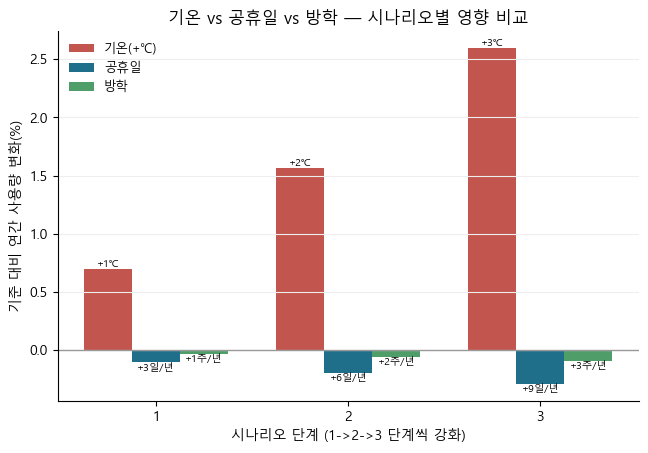

In [9]:
# 종합 비교: 기온 vs 공휴일 vs 방학을 "1->2->3단계"로 맞춰 한 그래프에
fig, ax = plt.subplots(figsize=(7.5, 4.8))
width = 0.25
temp_steps = (temp_scen[temp_scen["\u0394T(\u2103)"].isin([1, 2, 3])]
              .sort_values("\u0394T(\u2103)")
              .rename(columns={"기준 대비 %": "pct"})
              .assign(구분="기온(+\u2103)"))
temp_steps["단계"] = [1, 2, 3]
temp_steps["라벨"] = temp_steps["\u0394T(\u2103)"].map(lambda v: f"+{v:.0f}\u2103")
cal_steps = cal_scen.copy()
cal_steps["단계"] = cal_steps.groupby("구분").cumcount() + 1
cal_steps["pct"] = -cal_steps["절감율(%)"]
cal_steps["라벨"] = cal_steps["시나리오"].str.replace(r"^\S+\s+", "", regex=True)

combo = pd.concat([temp_steps[["구분", "단계", "라벨", "pct"]], cal_steps[["구분", "단계", "라벨", "pct"]]])
colors = {"기온(+\u2103)": "#c2554d", "공휴일": "#1f6f8b", "방학": "#4f9d69"}
for i, (grp, color) in enumerate(colors.items()):
    sub = combo[combo["구분"] == grp].sort_values("단계")
    x = sub["단계"].to_numpy() + (i - 1) * width
    ax.bar(x, sub["pct"], width=width, color=color, label=grp)
    for xi, yi, lab in zip(x, sub["pct"], sub["라벨"]):
        ax.text(xi, yi, lab, ha="center", va="bottom" if yi >= 0 else "top", fontsize=7.5)

ax.axhline(0, color="#999999", lw=1)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("시나리오 단계 (1->2->3 단계씩 강화)")
ax.set_ylabel("기준 대비 연간 사용량 변화(%)")
ax.set_title("기온 vs 공휴일 vs 방학 — 시나리오별 영향 비교")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.grid(axis="y", color="#eeeeee", lw=0.8)
plt.show()

세 변수는 단위가 달라(℃/추가휴무일/추가방학주) 절대 비교는 안 되지만, **기온의
영향력이 압도적으로 크다**: +3℃는 +2.6%인데 추가 휴무일 9일/년은 -0.29%, 추가 방학
3주/년은 -0.09%에 그친다 — 캘린더 정책만으로는 기온상승분을 상쇄하기 어렵다. 공휴일
효과가 방학보다 하루 단위로 3배 이상 큰 것(-13.3% vs -1.8%)은, 방학 중에는 학교가
완전히 멈추지 않고 기저부하(연구실·서버·냉난방)가 남아있는 반면 공휴일은 더 확실히
활동이 준다는 뜻으로 해석된다.

## 4. 전기요금 구조 및 시나리오별 비용

`reference/parameters.md`·`electricity_rates.png`·`carbon_credit_prices.png` 기준 —
계약종별 **교육용(을)고압A**, 계약전력 **30,000kW**.

| 기본요금(원/kW) | 시간대 | 여름철(6-8월) | 봄가을철(3-5,9-10월) | 겨울철(11-2월) |
| --- | --- | --- | --- | --- |
| 6,980 | 경부하 | 72.0 | 72.0 | 76.0 |
| | 중간부하 | 116.7 | 86.4 | 115.2 |
| | 최대부하 | 182.6 | 106.9 | 153.9 |

**기본요금**(6,980원/kW × 30,000kW ≈ 연 251억원)은 계약전력 기준으로 **시나리오와 무관하게
고정** — 시뮬레이션한 peak가 30,000kW를 넘지 않는 한 그렇다. 시나리오 간 비용 차이는
**전력량요금**에서만 발생한다.

5년 daily 모델에는 시간대 구분이 없어서, `data/data.csv`의 실제 15분 데이터로 캠퍼스
부하가 시간대별로 어떻게 걸리는지 계산해 **계절별 가중평균 단가**를 구한 뒤 5년 모델의
일별 예측값에 곱한다(미래에도 하루 안의 부하 패턴은 안 바뀐다는 가정). 탄소가격은
KAU30(2030년물, 9/25 종가) 29,450원/tCO2eq — 2050년대 가격 정보는 없어 동일가로 가정.

In [10]:
RATE_TABLE = {"summer": {"off": 72.0, "mid": 116.7, "peak": 182.6},
              "spring_fall": {"off": 72.0, "mid": 86.4, "peak": 106.9},
              "winter": {"off": 76.0, "mid": 115.2, "peak": 153.9}}
BASIC_RATE, CONTRACT_KW, CARBON_PRICE = 6980, 30000, 29450


def season_of(month):
    return "summer" if month in (6, 7, 8) else "winter" if month in (11, 12, 1, 2) else "spring_fall"


def tou_band(month, hour, minute):
    t = hour + minute / 60
    if t >= 23 or t < 9:
        return "off"
    peak = [(10, 12), (17, 20), (22, 23)] if season_of(month) == "winter" else [(10, 12), (13, 17)]
    return "peak" if any(lo <= t < hi for lo, hi in peak) else "mid"


d15 = pd.read_csv("data/data.csv", parse_dates=["date"])
d15["month"] = d15["date"].dt.month
d15["hour"] = d15["time"].str.slice(0, 2).astype(int) % 24
d15["minute"] = d15["time"].str.slice(3, 5).astype(int)
d15["season"] = d15["month"].map(season_of)
d15["band"] = [tou_band(m, h, mi) for m, h, mi in zip(d15["month"], d15["hour"], d15["minute"])]
d15["rate"] = [RATE_TABLE[s][b] for s, b in zip(d15["season"], d15["band"])]
d15["cost"] = d15["usage_kwh"] * d15["rate"]

BLENDED_RATE = (d15.groupby("season")["cost"].sum() / d15.groupby("season")["usage_kwh"].sum()).to_dict()
print("계절별 실측부하 가중평균 단가(원/kWh):", {k: round(v, 1) for k, v in BLENDED_RATE.items()})
print(f"검증: 1년 실제 전력량요금 {d15['cost'].sum()/1e8:,.1f}억원 "
      f"(단가 {d15['cost'].sum()/d15['usage_kwh'].sum():.1f}원/kWh)")
print(f"기본요금(참고, 고정): 연 {BASIC_RATE*CONTRACT_KW*12/1e8:,.1f}억원")

계절별 실측부하 가중평균 단가(원/kWh): {'spring_fall': 86.8, 'summer': 119.2, 'winter': 110.3}
검증: 1년 실제 전력량요금 101.2억원 (단가 104.2원/kWh)
기본요금(참고, 고정): 연 25.1억원


In [11]:
def energy_cost(usage_series, dates):
    # 일별 kWh 배열 -> 계절별 블렌드 단가를 곱한 "연평균" 전력량요금(원)
    rates = pd.to_datetime(dates).dt.month.map(season_of).map(BLENDED_RATE)
    return (usage_series * rates.to_numpy()).sum() / n_years


cost_rows = []
for name, dt in SCENARIOS_TEMP.items():
    kwh = usage_by_scn[name]
    cost_rows.append({"구분": "기온", "시나리오": name, "연평균 MWh": kwh.sum() / 1000 / n_years,
                       "전력량요금(억원)": energy_cost(kwh, est["date"]) / 1e8})
for label, col, steps, unit in CAL_SCENARIOS:
    for step in steps:
        n_days = step * (7 if unit == "주/년" else 1)
        sc, _ = flip_scenario(col, round(n_days * n_years))
        kwh = np.exp(res.predict(sc)) * smear
        cost_rows.append({"구분": label, "시나리오": f"{label} +{step}{unit}", "연평균 MWh": kwh.sum() / 1000 / n_years,
                           "전력량요금(억원)": energy_cost(kwh, sc["date"]) / 1e8})

cost_all = pd.DataFrame(cost_rows)
base_cost = cost_all.loc[cost_all["시나리오"] == "+0\u2103(기준)", "전력량요금(억원)"].iloc[0]
cost_all["비용 증감(억원)"] = cost_all["전력량요금(억원)"] - base_cost
cost_all["\u0394tCO2eq"] = (cost_all["연평균 MWh"] - base_mwh) * CO2_FACTOR
cost_all["탄소비용 증감(억원)"] = cost_all["\u0394tCO2eq"] * CARBON_PRICE / 1e8
cost_all["총 비용증감(억원)"] = cost_all["비용 증감(억원)"] + cost_all["탄소비용 증감(억원)"]
cost_all.style.format({"연평균 MWh": "{:,.0f}", "전력량요금(억원)": "{:,.2f}", "비용 증감(억원)": "{:+,.3f}",
                        "\u0394tCO2eq": "{:+,.0f}", "탄소비용 증감(억원)": "{:+,.4f}", "총 비용증감(억원)": "{:+,.3f}"})

,구분,시나리오,연평균 MWh,전력량요금(억원),비용 증감(억원),ΔtCO2eq,탄소비용 증감(억원),총 비용증감(억원)
0,기온,+0℃(기준),"87,536",90.98,+0.000,+0,+0.0000,+0.000
1,기온,+1℃,"88,147",91.62,+0.638,+278,+0.0818,+0.720
2,기온,+2℃,"88,904",92.40,+1.420,+621,+0.1830,+1.603
3,기온,+3℃,"89,808",93.32,+2.348,"+1,032",+0.3039,+2.651
4,기온,+4℃,"90,860",94.40,+3.423,"+1,510",+0.4446,+3.868
5,기온,SSP2-4.5_2030s,"88,287",91.76,+0.783,+341,+0.1005,+0.884
6,기온,SSP2-4.5_2050s,"89,073",92.57,+1.594,+698,+0.2056,+1.799
7,기온,SSP5-8.5_2030s,"88,432",91.91,+0.934,+407,+0.1199,+1.054
8,기온,SSP5-8.5_2050s,"89,615",93.13,+2.150,+944,+0.2781,+2.428
9,공휴일,공휴일 +3일/년,"87,443",90.90,-0.081,-42,-0.0124,-0.093


기온 시나리오는 비용이 늘고(+4℃ 최대 +3.9억원/년) 공휴일·방학 시나리오는 비용이
준다(공휴일 +9일/년 최대 -0.25억원/년) — 방향이 반대라 하나의 표에서 한눈에 비교된다.
전력량요금 변화가 탄소비용 변화보다 훨씬 커서, 총비용은 사실상 전력량요금이 좌우한다.

## 5. 복합재해 유의성 검토 — 폭염만이 아니다 (레질리언스)

`data_long.csv`의 **모든** 특보·주의보 플래그(+대표 연속 기상변수 2개)를 최종 모델에
하나씩 추가해 유의성을 확인한다. 표본에 0건인 특보(강풍경보·태풍경보·황사경보)는 검정
자체가 불가능해 제외.

In [12]:
ALL_FLAGS = ["strong_wind_warning", "strong_wind_advisory", "dry_advisory", "heavy_snow_warning",
             "heavy_snow_advisory", "tropical_night", "typhoon_warning", "typhoon_advisory",
             "heat_wave_warning", "heat_wave_advisory", "cold_wave_warning", "cold_wave_advisory",
             "heavy_rain_warning", "heavy_rain_advisory", "yellow_dust_warning"]
EXTRA_CONTINUOUS = ["wind_speed_ms", "pressure_sea_hpa"]

hazard_rows = []
for f in ALL_FLAGS:
    n = int(est[f].sum())
    if n == 0:
        hazard_rows.append({"변수": f, "n": n, "효과(%)": np.nan, "p-value": np.nan, "비고": "표본 0건, 검정 불가"})
        continue
    r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
    hazard_rows.append({"변수": f, "n": n, "효과(%)": (np.exp(r.params[f]) - 1) * 100, "p-value": r.pvalues[f],
                         "비고": "" if n >= 15 else "n<15, 신뢰 낮음"})
for f in EXTRA_CONTINUOUS:
    r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
    hazard_rows.append({"변수": f, "n": len(est), "효과(%)": np.nan, "p-value": r.pvalues[f],
                         "비고": f"연속변수, 로그계수={r.params[f]:.5f}/단위"})

hazard_tab = pd.DataFrame(hazard_rows).sort_values("p-value", na_position="last")
hazard_tab["유의(p<0.05)"] = hazard_tab["p-value"] < 0.05
hazard_tab.style.format({"효과(%)": "{:+.2f}%", "p-value": "{:.3f}"}, na_rep="-")

C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:17: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\1404139137.py:17: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = smf.ols(formula + f" + {f}", data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


,변수,n,효과(%),p-value,비고,유의(p<0.05)
5,tropical_night,17,+6.95%,0.000,,True
4,heavy_snow_advisory,23,-2.61%,0.023,,True
15,wind_speed_ms,1819,-,0.035,"연속변수, 로그계수=-0.00417/단위",True
3,heavy_snow_warning,3,-2.76%,0.052,"n<15, 신뢰 낮음",False
1,strong_wind_advisory,31,-1.60%,0.128,,False
2,dry_advisory,66,-1.59%,0.183,,False
16,pressure_sea_hpa,1819,-,0.295,"연속변수, 로그계수=0.00050/단위",False
9,heat_wave_advisory,122,-1.58%,0.300,,False
10,cold_wave_warning,13,-0.90%,0.530,"n<15, 신뢰 낮음",False
13,heavy_rain_advisory,43,-0.36%,0.547,,False


**개별 투입**이라 서로 상관된 변수(폭염경보·주의보는 종종 같이 발효)가 있으면 계수가
같이 넣었을 때와 달라질 수 있다. 새로 유의하게 나온 건 **열대야**(+7.0%, p<0.001)와
**대설주의보**(-2.6%, p=0.02) — 둘 다 폭염특보와 함께 "다중재해" 모델로 재확인한다.

In [13]:
multi_formula = formula + " + heat_wave_advisory + heat_wave_warning + tropical_night + heavy_snow_advisory"
res_multi = smf.ols(multi_formula, data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})
multi_smear = np.exp(res_multi.resid).mean()

multi_vars = ["heat_wave_advisory", "heat_wave_warning", "tropical_night", "heavy_snow_advisory"]
pd.DataFrame({"n": [int(est[v].sum()) for v in multi_vars],
              "효과(%)": [(np.exp(res_multi.params[v]) - 1) * 100 for v in multi_vars],
              "p-value": [res_multi.pvalues[v] for v in multi_vars]}, index=multi_vars).style.format(
    {"효과(%)": "{:+.2f}%", "p-value": "{:.3f}"})

C:\Users\pjw04\AppData\Local\Temp\ipykernel_29600\268782402.py:2: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  res_multi = smf.ols(multi_formula, data=est).fit(cov_type="HAC", cov_kwds={"maxlags": 15})


,n,효과(%),p-value
heat_wave_advisory,122,-2.04%,0.103
heat_wave_warning,57,-0.27%,0.871
tropical_night,17,+7.52%,0.000
heavy_snow_advisory,23,-2.67%,0.021


**중요한 정정**: 4개를 같이 넣으니 `heat_wave_warning`의 효과가 -0.3%(p=0.87)로
사라진다 — 3절에서 폭염특보 자체는 최종 모델 기준 이미 비유의하다고 했는데, 만약 폭염
특보만 넣고 `heat_wave_warning`이 유의하게 나온 다른 분석이 있었다면 그건 경보급
폭염이 거의 항상 열대야를 동반해서, 열대야 효과가 경보 효과로 잘못 잡혔을 가능성이
크다는 뜻이다. **열대야**는 다중재해 모델에서도 +7.5%(p<0.001)로 견고하게 유지되고
**대설주의보**도 -2.7%(p=0.02)로 유지된다 — 이 둘로 "+N일/년" 시나리오·비용을
계산한다(공휴일·방학과 같은 방식, `flip_scenario` 재사용).

In [14]:
def cost_multi(df):
    kwh = np.exp(res_multi.predict(df)) * multi_smear
    return kwh.sum() / 1000 / n_years, energy_cost(kwh, df["date"])


base_mwh_multi, base_cost_multi = cost_multi(est)

HAZARD_SCENARIOS = [("열대야", "tropical_night", [5, 10]), ("대설주의보", "heavy_snow_advisory", [3, 6])]
extra_rows = []
for label, col, steps in HAZARD_SCENARIOS:
    for step in steps:
        sc, flipped = flip_scenario(col, round(step * n_years))
        mwh, cost = cost_multi(sc)
        d_mwh = mwh - base_mwh_multi
        extra_rows.append({"시나리오": f"{label} +{step}일/년", "flip 일수": flipped, "\u0394 MWh(연평균)": d_mwh,
                            "\u0394 전력량요금(억원)": (cost - base_cost_multi) / 1e8,
                            "\u0394 tCO2eq": d_mwh * CO2_FACTOR, "\u0394 탄소비용(억원)": d_mwh * CO2_FACTOR * CARBON_PRICE / 1e8})

extra_hazard = pd.DataFrame(extra_rows)
extra_hazard.style.format({"\u0394 MWh(연평균)": "{:+,.1f}", "\u0394 전력량요금(억원)": "{:+,.4f}",
                            "\u0394 tCO2eq": "{:+,.1f}", "\u0394 탄소비용(억원)": "{:+,.5f}"})

,시나리오,flip 일수,Δ MWh(연평균),Δ 전력량요금(억원),Δ tCO2eq,Δ 탄소비용(억원)
0,열대야 +5일/년,25,+82.1,+0.0733,+37.3,+0.01098
1,열대야 +10일/년,50,+159.4,+0.1534,+72.4,+0.02132
2,대설주의보 +3일/년,15,-18.7,-0.0162,-8.5,-0.00250
3,대설주의보 +6일/년,30,-34.4,-0.0318,-15.6,-0.00460


### 최종 요약

- **열대야**는 기후변화로 일수 자체가 늘어나는 추세라, 2·4절의 "일평균기온 상승"만으로는
  미래 비용을 과소평가할 수 있다 — 별도로 감안할 필요가 있는 채널.
- **대설주의보**는 유일하게 유의한 "비용을 줄이는" 특보 — 폭설로 인한 휴교·재택전환 효과.
- 강풍·건조·태풍·한파·호우 특보는 표본 안에서 유의한 별도 효과를 찾지 못했다(발생빈도가
  너무 낮거나, 기온·강수 통제변수가 효과를 이미 흡수했을 가능성).
- 기본요금(연 약 251억원)은 모든 시나리오에서 불변이므로, 이 노트북의 모든 비용 숫자는
  **전력량요금 + 탄소비용**의 한계 변화분이다.